In [14]:
# necessary modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from highlight_text import ax_text, fig_text
from pyfonts import load_google_font
import matplotlib.patches as patches
from pywaffle import Waffle
import math

import warnings
warnings.filterwarnings("ignore")

import os

In [3]:
# Nominations data
data_nominee = pd.read_csv(
    os.path.join(
        "..", "data", 
        "Nobel Peace Nominees (Decade).csv"
    )
)

df_nominee = data_nominee.copy()

df_nominee.head()

,Decade,Africa,America,Asia,Europe,Oceania,Total
0,1900,0,16,2,187,2,207
1,1910,0,42,2,190,0,234
2,1920,0,38,4,173,0,215
3,1930,3,71,24,240,3,341
4,1940,2,29,9,53,1,94


In [4]:
# transform data for easier plotting
df_nominee_melt = df_nominee.melt(
    id_vars=["Decade"], 
    value_vars=["Africa", "America", "Asia", "Europe", "Oceania"],
    var_name="region", 
    value_name="count"
)

df_nominee_melt.head()

,Decade,region,count
0,1900,Africa,0
1,1910,Africa,0
2,1920,Africa,0
3,1930,Africa,3
4,1940,Africa,2


In [9]:
# maximim area under cultivation & the decade
max_decade = (df_nominee[df_nominee["Total"] == df_nominee["Total"].max()]["Decade"]).values[0]
max_decade_count = (df_nominee[df_nominee["Total"] == df_nominee["Total"].max()]["Total"]).values[0]

In [26]:
max_decade_count

np.int64(348)

In [5]:
# labels for each foodgrain
region_labels = df_nominee_melt["region"].unique().tolist()
region_labels


['Africa', 'America', 'Asia', 'Europe', 'Oceania']

In [6]:
# fonts
mw_reg = load_google_font("Merriweather Sans")
mw_i = load_google_font("Merriweather Sans", italic=True)
mw_b = load_google_font("Merriweather Sans", weight=500)
mw_bi = load_google_font("Merriweather Sans", weight=500, italic=True)

In [7]:
# colors
colors = [
    "#B87C4C", # Africa
    "#EBCB90", # America
    "#5D688A", # Asia
    "#FAA533", # Europe
    "green",   # Oceania
]

bg = "#FFFDF6"
colors.append(bg)

In [8]:
# explainers
title_main = "<Coarse Cereals> Pushed Aside:\n<Rice> & <Wheat> Took Over India's Cultivated Area Since <1970>s"
title_sub = "Now rebranded as <Nutri-cereals>, they are at the center of India's revival efforts."
data_source = "Data: Area Under Cultivation (Lakh Hectares) - Reserve Bank of India"

In [18]:
waffle_rows = math.ceil(max_decade / waffle_columns)
waffle_rows

201

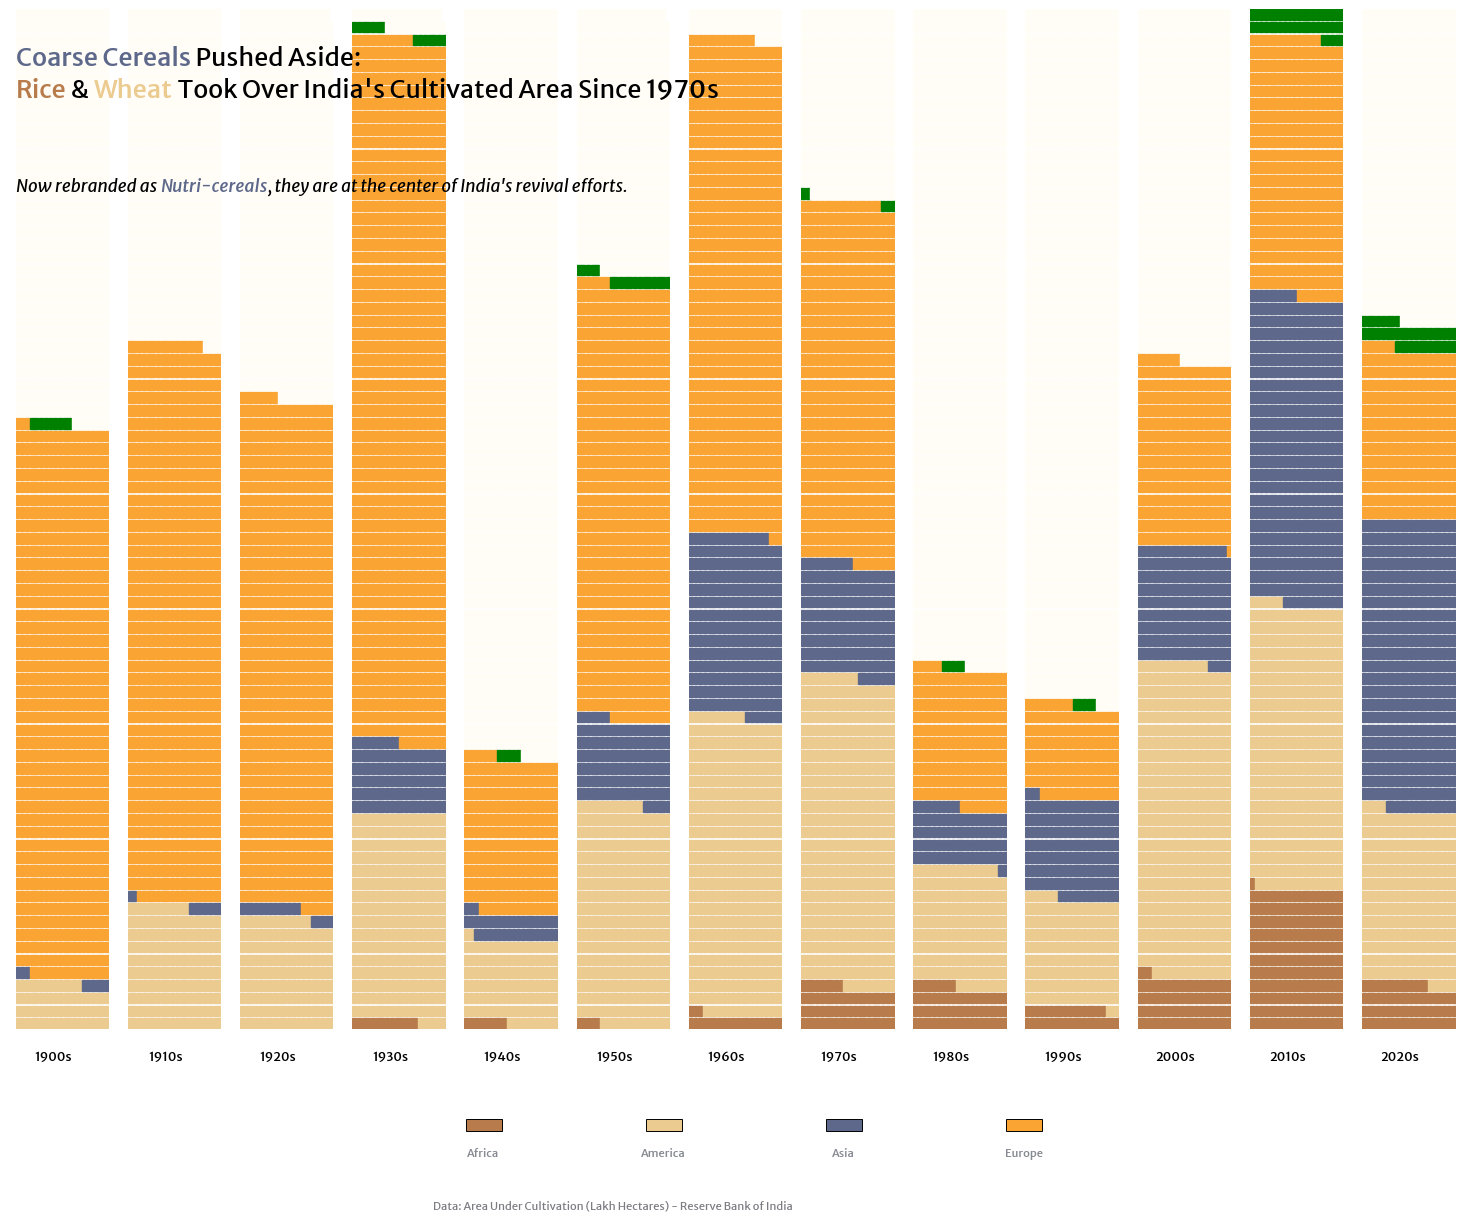

In [28]:
# plotting
ncols = df_nominee_melt["Decade"].nunique()

fig, axs = plt.subplots(ncols=ncols, figsize=(18, 12))

fig.subplots_adjust(left=0.1, right=0.9, top=0.95, bottom=0.1)
fig.set_facecolor("white")


for year, ax in zip(df_nominee_melt["Decade"].unique(), axs):
    values = list(df_nominee_melt[df_nominee_melt["Decade"] == year]["count"].values)
    values.append(max_decade_count - sum(values))
    
    Waffle.make_waffle(
    ax=ax,
    rows=80,
    columns=20,
    values=values,
    vertical=True,
    colors=colors,
  )
  
    ax.text(x=0.1, y=-0.03, s=str(year)+"s", fontsize=9, ha="center", fontweight="bold", font=mw_b)


# legend
legend_xy = [(0.35, 0.02), (0.45, 0.02), (0.55, 0.02), (0.65, 0.02)]
legend_colors = ["#B87C4C", "#EBCB90", "#5D688A", "#FAA533", "green"]
legend_text = ["Africa", "America", "Asia", "Europe", "Oceania"]
box_w, box_h = 0.02, 0.01
for xy, c, text in zip(legend_xy, legend_colors, legend_text):
    legend = patches.Rectangle(
        (xy[0], xy[1]- box_h/2), width=box_w, height=box_h,
        transform=fig.transFigure,
        edgecolor="black", facecolor=c,
        linewidth=0.7, alpha=1,
        clip_on=False, zorder=10
    )
    ax.add_patch(legend)
    fig_text(
        x=xy[0]+box_w/2, y=(xy[1])-0.018, s=text,
        size=8, color="#686D76", font=mw_b,
        ha="center", alpha=0.8
    )



# title
fig_text(
  x=0.1,
  y=0.92,
  s=title_main,
  size=18,
  font=mw_reg,
  highlight_textprops=[
      dict(font=mw_b, color=colors[2]),
      dict(font=mw_b, color=colors[0]),
      dict(font=mw_b, color=colors[1]),
      dict(font=mw_b)
  ],
)

# Sub-title
fig_text(
  x=0.1,
  y=0.81,
  s=title_sub,
  size=12.5,
  font=mw_i,
  highlight_textprops=[
      dict(font=mw_bi, color=colors[2])
  ],
)

# data source
fig_text(
  x=0.332,
  y=-0.042,
  s=data_source,
  size=8,
  font=mw_reg,
  color="#44444E",
  alpha=0.7,
  ha="left"
)

# plt.show()

# save data story
save_name = "test.jpeg"
plt.savefig(os.path.join("..", "viz", save_name), dpi=200, pad_inches=1, bbox_inches="tight")